# Poké-Catch · 02 · Experimento comparativo de modelos de clasificación

**Problema de predicción.** Dado un intento de captura, descrito por las características del Pokémon y del lanzamiento, predecir su clase: **captura** o **no captura**.

**Este notebook:**

1. Define las métricas y el criterio de selección **antes** de entrenar.
2. Reserva un conjunto de prueba que no se usa para elegir el modelo.
3. Compara 12 alternativas: algoritmos, selecciones de variables, una forma de preparar los datos y configuraciones.
4. Selecciona un modelo y justifica la elección.
5. Lo evalúa en el conjunto de prueba: matriz de confusión, resultados por clase y medida agregada.
6. Examina ejemplos de errores y los tipos de casos más difíciles.

Los datos y las decisiones de preparación vienen de `01_analisis_exploratorio.ipynb`.

## 0. Configuración y datos

In [1]:
import sys, time
from pathlib import Path

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pokecatch.py").exists())
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, brier_score_loss, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

import pokecatch as pc

plt.rcParams.update(pc.ESTILO)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
AZUL, NARANJA, GRIS, SEMILLA = pc.AZUL, pc.NARANJA, pc.GRIS, pc.SEMILLA

In [2]:
especies, intentos = pc.cargar_dataset()          # lee datos/procesados (o los genera si no existen)
datos = pc.unir(especies, intentos)

VE = pc.variables_especie(especies)                                    # 58 variables del Pokémon
X_lanz = pc.variables_lanzamiento(datos)                               # 17 variables del lanzamiento
X_lanz_m = pc.variables_lanzamiento(datos, con_multiplicador=True)     # + multiplicador_ball

PREPARACIONES = {
    "solo lanzamiento": X_lanz.astype(float),
    "A": pd.concat([datos[VE], X_lanz], axis=1).astype(float),      # Pokémon + lanzamiento
    "B": pd.concat([datos[VE], X_lanz_m], axis=1).astype(float),    # A + multiplicador de la ball
}
y = datos.captura.values
familias = datos.evolution_chain_id.values
print({k: v.shape for k, v in PREPARACIONES.items()})
print(f"Clase: {y.mean():.1%} captura, {1 - y.mean():.1%} no captura")

{'solo lanzamiento': (41000, 17), 'A': (41000, 75), 'B': (41000, 76)}
Clase: 48.4% captura, 51.6% no captura


## 1. Métricas y criterio de selección (definidos antes del experimento)

**Qué significa cada error para el jugador:**

| Error | Qué pasa | Consecuencia |
|---|---|---|
| **Falso positivo**: el modelo dice *captura* y el Pokémon se escapa | El jugador lanza confiado | Pierde la ball y el turno; el Pokémon puede atacar o huir |
| **Falso negativo**: el modelo dice *no captura* y se habría capturado | El jugador sigue debilitando | Pierde turnos y arriesga debilitar al Pokémon, con lo que lo pierde |

Los dos errores cuestan, y ninguno es claramente más grave que el otro. Por eso no optimizamos una sola clase.

| Métrica | Papel | Por qué |
|---|---|---|
| **F1 macro** | **Principal** (medida agregada) | Promedia el F1 de ambas clases con el mismo peso. Las clases están casi balanceadas (48 % / 52 %) pero no son idénticas, y queremos que el modelo sirva igual para las dos |
| Precisión, recobrado y F1 **por clase** | Diagnóstico | Muestran qué tipo de error comete cada alternativa |
| **Brier** | Desempate | La aplicación mostraría una probabilidad, así que importa que sea confiable. Menor es mejor |
| AUC | Apoyo | Mide cuánto separa el modelo ambas clases, sin depender del umbral |
| Exactitud | Solo informativa | No se usa para decidir |

**Criterio de selección:**

1. Gana la alternativa con mayor **F1 macro** promedio en validación cruzada.
2. Si dos alternativas difieren en menos que la desviación entre particiones, se consideran **empatadas**. En ese caso se elige la de mejor **Brier** y, si siguen empatadas, la **más simple**.
3. Antes de aceptarla, se revisan sus resultados por clase y casos concretos.

**Referencia: el techo.** Como la clase tiene azar (notebook 01, sección 7), ni un modelo perfecto acierta siempre. El techo es la propia fórmula usando el ratio real. No es una alternativa del experimento, porque usa información que el modelo no tiene.

## 2. Separación de los datos

- **Conjunto de prueba (20 %)**: se reserva ahora y se usa **una sola vez**, al final, con el modelo ya elegido.
- **Conjunto de desarrollo (80 %)**: sirve para entrenar y comparar las alternativas con validación cruzada de 5 particiones.

Ambas separaciones se hacen **por familia evolutiva**. Si Charmander quedara en entrenamiento y Charizard en prueba, el modelo reconocería a un pariente y la evaluación sería optimista. Así, el conjunto de prueba contiene solo especies de familias que el modelo nunca vio, que es el caso de uso real.

In [3]:
idx_des, idx_pru = next(GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEMILLA).split(datos, y, familias))
y_des, y_pru = y[idx_des], y[idx_pru]
fam_des, fam_pru = familias[idx_des], familias[idx_pru]
cv = GroupKFold(n_splits=5)

print(pd.DataFrame({
    "registros": [len(idx_des), len(idx_pru)],
    "familias": [len(set(fam_des)), len(set(fam_pru))],
    "especies": [datos.species_id.iloc[idx_des].nunique(), datos.species_id.iloc[idx_pru].nunique()],
    "% captura": [round(100 * y_des.mean(), 1), round(100 * y_pru.mean(), 1)],
}, index=["desarrollo", "prueba"]).to_string())
print("\nFamilias en ambos conjuntos:", len(set(fam_des) & set(fam_pru)))

            registros  familias  especies  % captura
desarrollo      32720       432       818       48.1
prueba           8280       108       207       49.4

Familias en ambos conjuntos: 0


## 3. Alternativas comparadas

El experimento varía tres cosas, siempre con las mismas particiones para que las diferencias se deban a la alternativa:

**Selección de variables**

- *Solo lanzamiento*: 17 variables. Responde si las características del Pokémon aportan.
- *Pokémon + lanzamiento* (preparación A): 75 variables.

**Preparación de datos**

- *A*: variables tal como salen del notebook 01.
- *B*: A más `multiplicador_ball`, el multiplicador público de la ball en ese contexto (notebook 01, sección 5.2).

**Algoritmo**

| Algoritmo | Por qué se incluye |
|---|---|
| Clase mayoritaria | Línea base: cualquier modelo útil debe superarla |
| Regresión logística | Modelo lineal simple e interpretable |
| Árbol de decisión | Interpretable; captura interacciones simples |
| Random Forest | Promedio de muchos árboles; más estable |
| Gradient Boosting | Árboles en secuencia; suele rendir mejor en datos tabulares |

Después se comparan tres **configuraciones** del algoritmo con mejor resultado.

In [4]:
ALGORITMOS = {
    "Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.5)),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=SEMILLA),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=SEMILLA),
    "Gradient Boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=31,
                                                        l2_regularization=1.0, random_state=SEMILLA),
}

def metricas(y_real, p):
    pred = (p >= 0.5).astype(int)
    return {"F1 macro": f1_score(y_real, pred, average="macro"),
            "Brier": brier_score_loss(y_real, p),
            "AUC": roc_auc_score(y_real, p) if len(np.unique(p)) > 1 else 0.5,
            "Exactitud": accuracy_score(y_real, pred),
            "Prec. captura": precision_score(y_real, pred, zero_division=0),
            "Rec. captura": recall_score(y_real, pred),
            "Prec. no captura": precision_score(y_real, pred, pos_label=0, zero_division=0),
            "Rec. no captura": recall_score(y_real, pred, pos_label=0)}

def validar(modelo, X):
    # Validación cruzada por familia dentro del conjunto de desarrollo
    Xd = X.iloc[idx_des]
    por_particion, p_oof = [], np.zeros(len(idx_des))
    for tr, va in cv.split(Xd, y_des, fam_des):
        m = clone(modelo).fit(Xd.iloc[tr], y_des[tr])
        p_oof[va] = m.predict_proba(Xd.iloc[va])[:, 1]
        por_particion.append(metricas(y_des[va], p_oof[va]))
    return pd.DataFrame(por_particion), p_oof

resultados, detalle = [], {}
def registrar(nombre, algoritmo, preparacion, modelo):
    t0 = time.time()
    df, p_oof = validar(modelo, PREPARACIONES[preparacion])
    detalle[nombre] = df
    fila = {"alternativa": nombre, "algoritmo": algoritmo, "preparación": preparacion,
            "variables": PREPARACIONES[preparacion].shape[1]}
    fila.update(df.mean().to_dict())
    fila["F1 macro (desv.)"] = df["F1 macro"].std(ddof=0)
    resultados.append(fila)
    print(f"{nombre:45s} F1 macro {fila['F1 macro']:.3f} ± {fila['F1 macro (desv.)']:.3f}   ({time.time() - t0:.0f} s)")

## 4. Ejecución del experimento

### 4.1 Algoritmo × selección de variables × preparación

In [5]:
registrar("Clase mayoritaria", "Línea base", "A", DummyClassifier(strategy="most_frequent"))
registrar("Regresión logística · solo lanzamiento", "Regresión logística", "solo lanzamiento", ALGORITMOS["Regresión logística"])
for prep in ["A", "B"]:
    for nombre, modelo in ALGORITMOS.items():
        registrar(f"{nombre} · {prep}", nombre, prep, modelo)

Clase mayoritaria                             F1 macro 0.342 ± 0.006   (0 s)


Regresión logística · solo lanzamiento        F1 macro 0.607 ± 0.005   (0 s)


Regresión logística · A                       F1 macro 0.702 ± 0.010   (1 s)


Árbol de decisión · A                         F1 macro 0.681 ± 0.008   (1 s)


Random Forest · A                             F1 macro 0.707 ± 0.010   (13 s)


Gradient Boosting · A                         F1 macro 0.728 ± 0.006   (11 s)


Regresión logística · B                       F1 macro 0.725 ± 0.006   (1 s)


Árbol de decisión · B                         F1 macro 0.709 ± 0.004   (1 s)


Random Forest · B                             F1 macro 0.733 ± 0.007   (14 s)


Gradient Boosting · B                         F1 macro 0.735 ± 0.004   (10 s)


In [6]:
COLS = ["F1 macro", "F1 macro (desv.)", "Brier", "AUC", "Exactitud",
        "Prec. captura", "Rec. captura", "Prec. no captura", "Rec. no captura"]
tabla = pd.DataFrame(resultados).set_index("alternativa")
tabla[["variables"] + COLS].round(3)

,variables,F1 macro,F1 macro (desv.),Brier,AUC,Exactitud,Prec. captura,Rec. captura,Prec. no captura,Rec. no captura
alternativa,,,,,,,,,,
Clase mayoritaria,75,0.342,0.006,0.481,0.500,0.519,0.000,0.000,0.519,1.000
Regresión logística · solo lanzamiento,17,0.607,0.005,0.232,0.653,0.611,0.609,0.537,0.613,0.680
Regresión logística · A,75,0.702,0.010,0.193,0.775,0.702,0.689,0.694,0.714,0.710
Árbol de decisión · A,75,0.681,0.008,0.201,0.753,0.684,0.692,0.620,0.679,0.743
Random Forest · A,75,0.707,0.010,0.189,0.784,0.709,0.723,0.640,0.699,0.773
Gradient Boosting · A,75,0.728,0.006,0.178,0.806,0.730,0.742,0.672,0.720,0.784
Regresión logística · B,76,0.725,0.006,0.182,0.802,0.725,0.714,0.714,0.735,0.736
Árbol de decisión · B,76,0.709,0.004,0.189,0.783,0.711,0.723,0.648,0.702,0.769
Random Forest · B,76,0.733,0.007,0.179,0.810,0.735,0.742,0.687,0.729,0.778


In [7]:
piv = tabla[tabla.preparación.isin(["A", "B"]) & (tabla.algoritmo != "Línea base")].pivot(
    index="algoritmo", columns="preparación", values="F1 macro").reindex(list(ALGORITMOS))
piv["mejora con B"] = piv.B - piv.A
print("F1 macro por algoritmo y preparación:")
print(piv.round(3).to_string())

F1 macro por algoritmo y preparación:
preparación              A      B  mejora con B
algoritmo                                      
Regresión logística  0.702  0.725         0.023
Árbol de decisión    0.681  0.709         0.027
Random Forest        0.707  0.733         0.026
Gradient Boosting    0.728  0.735         0.007


**Lectura:**

- **Las características del Pokémon aportan mucho.** Con el mismo algoritmo, pasar de *solo lanzamiento* a *Pokémon + lanzamiento* sube el F1 macro de 0,61 a 0,70.
- **La preparación B mejora a todos los algoritmos**, entre 0,007 y 0,027 de F1 macro. Gradient Boosting es el que menos gana, porque ya descubría por su cuenta parte de las condiciones de las balls especiales.
- **Gradient Boosting es el mejor algoritmo** con ambas preparaciones, aunque con B el Random Forest queda muy cerca.
- **Todos los modelos de árboles son conservadores:** el recobrado de *captura* (0,62 a 0,69) es menor que el de *no captura* (0,74 a 0,79). La regresión logística reparte los errores de forma más pareja, pero con menor F1 macro.

### 4.2 Configuraciones de Gradient Boosting (con preparación B)

Se varía el tamaño de los árboles (número máximo de hojas). Árboles más chicos dan un modelo más simple.

In [8]:
for hojas in [4, 8]:
    registrar(f"Gradient Boosting · B · {hojas} hojas", "Gradient Boosting", "B",
              HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=hojas,
                                             l2_regularization=1.0, random_state=SEMILLA))
tabla = pd.DataFrame(resultados).set_index("alternativa")
tabla = tabla.rename(index={"Gradient Boosting · B": "Gradient Boosting · B · 31 hojas",
                            "Gradient Boosting · A": "Gradient Boosting · A · 31 hojas"})
detalle["Gradient Boosting · B · 31 hojas"] = detalle["Gradient Boosting · B"]
detalle["Gradient Boosting · A · 31 hojas"] = detalle["Gradient Boosting · A"]
tabla[tabla.index.str.contains("Gradient Boosting · B")][COLS].round(4)

Gradient Boosting · B · 4 hojas               F1 macro 0.734 ± 0.005   (7 s)


Gradient Boosting · B · 8 hojas               F1 macro 0.734 ± 0.004   (8 s)


,F1 macro,F1 macro (desv.),Brier,AUC,Exactitud,Prec. captura,Rec. captura,Prec. no captura,Rec. no captura
alternativa,,,,,,,,,
Gradient Boosting · B · 31 hojas,0.7347,0.0043,0.1753,0.8118,0.7370,0.7526,0.6748,0.7248,0.7942
Gradient Boosting · B · 4 hojas,0.7335,0.0055,0.1759,0.8114,0.7349,0.7378,0.6958,0.7321,0.7707
Gradient Boosting · B · 8 hojas,0.7342,0.0040,0.1747,0.8128,0.7361,0.7467,0.6828,0.7275,0.7851


### 4.3 Comparación de todas las alternativas

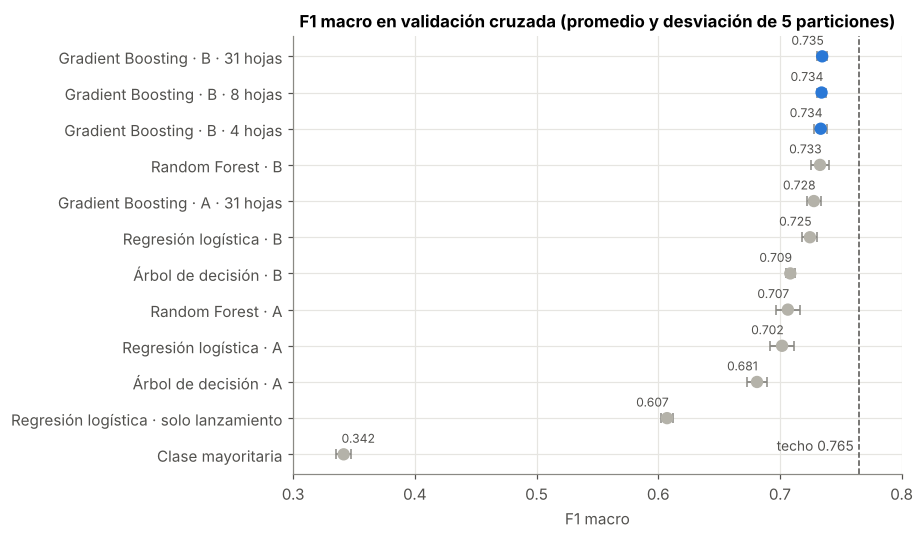

Techo en las mismas particiones: {'F1 macro': 0.765, 'Brier': 0.153, 'AUC': 0.853, 'Exactitud': 0.767}


,F1 macro,F1 macro (desv.),Brier,AUC,Exactitud,Prec. captura,Rec. captura,Prec. no captura,Rec. no captura
alternativa,,,,,,,,,
Gradient Boosting · B · 31 hojas,0.735,0.004,0.175,0.812,0.737,0.753,0.675,0.725,0.794
Gradient Boosting · B · 8 hojas,0.734,0.004,0.175,0.813,0.736,0.747,0.683,0.727,0.785
Gradient Boosting · B · 4 hojas,0.734,0.005,0.176,0.811,0.735,0.738,0.696,0.732,0.771
Random Forest · B,0.733,0.007,0.179,0.810,0.735,0.742,0.687,0.729,0.778
Gradient Boosting · A · 31 hojas,0.728,0.006,0.178,0.806,0.730,0.742,0.672,0.720,0.784
Regresión logística · B,0.725,0.006,0.182,0.802,0.725,0.714,0.714,0.735,0.736
Árbol de decisión · B,0.709,0.004,0.189,0.783,0.711,0.723,0.648,0.702,0.769
Random Forest · A,0.707,0.010,0.189,0.784,0.709,0.723,0.640,0.699,0.773
Regresión logística · A,0.702,0.010,0.193,0.775,0.702,0.689,0.694,0.714,0.710


In [9]:
p_real = np.clip(datos.p_real.values, 1e-6, 1 - 1e-6)
techo_cv = pd.DataFrame([metricas(y_des[va], p_real[idx_des][va]) for _, va in cv.split(idx_des, y_des, fam_des)]).mean()

orden = tabla.sort_values("F1 macro")
fig, ax = plt.subplots(figsize=(8.5, 5))
mejor_nombre = orden.index[-1]
ax.errorbar(orden["F1 macro"], range(len(orden)), xerr=orden["F1 macro (desv.)"], fmt="none", ecolor="#8a8984", lw=1.2, capsize=3)
ax.scatter(orden["F1 macro"], range(len(orden)), s=50, zorder=3,
           color=[AZUL if "Gradient Boosting · B" in n else GRIS for n in orden.index])
ax.axvline(techo_cv["F1 macro"], color="#52514e", ls="--", lw=1)
ax.text(techo_cv["F1 macro"] - 0.004, 0.1, f"techo {techo_cv['F1 macro']:.3f}", ha="right", color="#52514e", fontsize=9)
for i, (n, v) in enumerate(orden["F1 macro"].items()):
    ax.text(v + 0.012 if v < 0.5 else v - 0.012, i + 0.32, f"{v:.3f}", ha="center", fontsize=8, color="#52514e")
ax.set_yticks(range(len(orden)), orden.index)
ax.set(title="F1 macro en validación cruzada (promedio y desviación de 5 particiones)", xlabel="F1 macro", xlim=(0.3, 0.8))
plt.tight_layout(); plt.show()

print("Techo en las mismas particiones:", techo_cv[["F1 macro", "Brier", "AUC", "Exactitud"]].round(3).to_dict())
tabla.sort_values("F1 macro", ascending=False)[COLS].round(3)

## 5. Selección del modelo

In [10]:
top = tabla.sort_values("F1 macro", ascending=False)
lider = top.iloc[0]
empatadas = top[top["F1 macro"] >= lider["F1 macro"] - lider["F1 macro (desv.)"]]
print(f"Mayor F1 macro: {top.index[0]} ({lider['F1 macro']:.4f} ± {lider['F1 macro (desv.)']:.4f})")
print(f"\nAlternativas a menos de una desviación del líder (empatadas): {len(empatadas)}")
print(empatadas[["F1 macro", "F1 macro (desv.)", "Brier", "AUC"]].round(4).to_string())

# F1 macro por partición de las empatadas: ¿alguna gana de forma consistente?
print("\nF1 macro por partición:")
print(pd.DataFrame({n: detalle[n]["F1 macro"] for n in empatadas.index}).round(4).to_string())

Mayor F1 macro: Gradient Boosting · B · 31 hojas (0.7347 ± 0.0043)

Alternativas a menos de una desviación del líder (empatadas): 4
                                  F1 macro  F1 macro (desv.)   Brier     AUC
alternativa                                                                 
Gradient Boosting · B · 31 hojas    0.7347            0.0043  0.1753  0.8118
Gradient Boosting · B · 8 hojas     0.7342            0.0040  0.1747  0.8128
Gradient Boosting · B · 4 hojas     0.7335            0.0055  0.1759  0.8114
Random Forest · B                   0.7329            0.0074  0.1789  0.8097

F1 macro por partición:
   Gradient Boosting · B · 31 hojas  Gradient Boosting · B · 8 hojas  Gradient Boosting · B · 4 hojas  Random Forest · B
0                            0.7285                           0.7281                           0.7244             0.7221
1                            0.7320                           0.7312                           0.7312             0.7274
2                 

**Decisión: Gradient Boosting con preparación B y árboles de 8 hojas.**

Aplicando el criterio definido en la sección 1:

1. **F1 macro.** El valor más alto es el de Gradient Boosting · B · 31 hojas (0,735), pero cuatro alternativas quedan a menos de una desviación: las tres configuraciones de Gradient Boosting · B y Random Forest · B. Están **empatadas**, y ninguna gana en las cinco particiones.
2. **Brier (desempate).** La configuración de 8 hojas tiene el mejor Brier (0,1747) y el mejor AUC (0,813), es decir, las probabilidades más confiables. La diferencia con la de 31 hojas es mínima.
3. **Simplicidad.** Con desempeño equivalente, árboles de 8 hojas son un modelo más simple que árboles de 31, y mucho más liviano que un Random Forest de 300 árboles completos.

Aquí las métricas favorecen alternativas distintas: el F1 macro más alto es de la configuración de 31 hojas, y el mejor Brier y AUC, de la de 8. La diferencia en F1 macro (0,0005) es ocho veces menor que la variación entre particiones, así que no es evidencia a favor de ninguna; por eso decide el desempate.

**Por qué no las otras:**

- *Regresión logística · B* es más interpretable y queda cerca (F1 macro 0,725), pero está fuera del empate y tiene peor Brier (0,182).
- *Random Forest · B* está en el empate, pero pierde el desempate por Brier (0,179).
- *Árbol de decisión* queda por debajo en todas las métricas.
- *Preparación A*: todas rinden menos que su equivalente con B.

**Revisión por clase.** El modelo elegido es **conservador**: detecta mejor la *no captura* (recobrado 0,79) que la *captura* (0,68). A cambio, cuando dice *captura* acierta el 75 % de las veces. Para el jugador esto significa pocas balls desperdiciadas, al costo de debilitar a veces de más. Lo aceptamos porque las probabilidades están bien calibradas (sección 8) y el umbral de 0,5 es el natural; mover el umbral para equilibrar los errores queda como ajuste posible para la aplicación.

In [11]:
ELEGIDO = "Gradient Boosting · B · 8 hojas"
modelo_final = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=8,
                                              l2_regularization=1.0, random_state=SEMILLA)
X = PREPARACIONES["B"]
modelo_final.fit(X.iloc[idx_des], y_des)            # se entrena con todo el conjunto de desarrollo
print("Modelo elegido:", ELEGIDO)
print(tabla.loc[ELEGIDO, COLS].round(3).to_string())

Modelo elegido: Gradient Boosting · B · 8 hojas
F1 macro            0.734
F1 macro (desv.)    0.004
Brier               0.175
AUC                 0.813
Exactitud           0.736
Prec. captura       0.747
Rec. captura        0.683
Prec. no captura    0.727
Rec. no captura     0.785


## 6. Evaluación final en el conjunto de prueba

El conjunto de prueba se usa aquí por primera y única vez. Son 8 280 intentos de 108 familias evolutivas que no participaron en el entrenamiento ni en la selección.

In [12]:
p_pru = modelo_final.predict_proba(X.iloc[idx_pru])[:, 1]
pred_pru = (p_pru >= 0.5).astype(int)

print("Resultados por clase (conjunto de prueba)\n")
print(classification_report(y_pru, pred_pru, target_names=pc.CLASES, digits=3))

Resultados por clase (conjunto de prueba)

              precision    recall  f1-score   support

  no captura      0.738     0.809     0.772      4186
     captura      0.784     0.706     0.743      4094

    accuracy                          0.758      8280
   macro avg      0.761     0.758     0.758      8280
weighted avg      0.761     0.758     0.758      8280



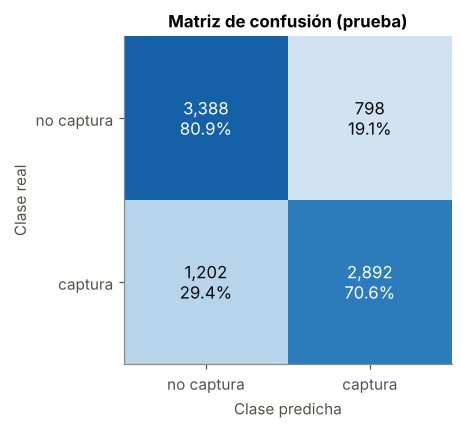

Falsos positivos (dice captura y se escapa): 798
Falsos negativos (dice no captura y se capturaba): 1,202


In [13]:
cm = confusion_matrix(y_pru, pred_pru)
cmn = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n{cmn[i, j]:.1%}", ha="center", va="center", fontsize=11,
                color="white" if cmn[i, j] > 0.55 else "#0b0b0b")
ax.set_xticks([0, 1], pc.CLASES); ax.set_yticks([0, 1], pc.CLASES)
ax.set(title="Matriz de confusión (prueba)", xlabel="Clase predicha", ylabel="Clase real"); ax.grid(False)
plt.tight_layout(); plt.show()
print(f"Falsos positivos (dice captura y se escapa): {cm[0, 1]:,}")
print(f"Falsos negativos (dice no captura y se capturaba): {cm[1, 0]:,}")

In [14]:
base = DummyClassifier(strategy="most_frequent").fit(X.iloc[idx_des], y_des)
comparacion = pd.DataFrame({
    "Clase mayoritaria": metricas(y_pru, base.predict_proba(X.iloc[idx_pru])[:, 1]),
    "Modelo elegido (validación cruzada)": tabla.loc[ELEGIDO, list(metricas(y_pru, p_pru))].to_dict(),
    "Modelo elegido (prueba)": metricas(y_pru, p_pru),
    "Techo (prueba)": metricas(y_pru, p_real[idx_pru]),
}).T[["F1 macro", "Brier", "AUC", "Exactitud"]]
comparacion.round(3)

,F1 macro,Brier,AUC,Exactitud
Clase mayoritaria,0.336,0.494,0.500,0.506
Modelo elegido (validación cruzada),0.734,0.175,0.813,0.736
Modelo elegido (prueba),0.758,0.158,0.848,0.758
Techo (prueba),0.779,0.145,0.871,0.780


**Lectura:**

- En prueba, el modelo logra un **F1 macro de 0,758** y clasifica bien el **75,8 %** de los intentos, sin conocer el ratio de captura.
- El resultado en prueba es algo mejor que en validación cruzada (0,734). No es mérito del modelo: las especies que cayeron en prueba son un poco más fáciles de predecir, y el techo también sube (0,779 en prueba frente a 0,765 en validación). Lo comparable es la **distancia al techo**: 0,031 en validación y 0,021 en prueba. No hay señales de sobreajuste.
- **Por clase:** *no captura* tiene precisión 0,738 y recobrado 0,809; *captura*, precisión 0,784 y recobrado 0,706. Se confirma el comportamiento conservador: hay más falsos negativos (1 202) que falsos positivos (798).
- Cuando el modelo dice *captura*, acierta el 78 % de las veces.

## 7. Análisis de errores

### 7.1 ¿Cuántos errores son del modelo y cuántos del azar?

Como conocemos la probabilidad real de cada intento, podemos separar los errores en dos tipos:

- **Azar**: salió el resultado menos probable. Ni conociendo la probabilidad real se habría acertado.
- **Del modelo**: el resultado era el más probable, pero el modelo estimó mal la probabilidad.

                  intentos  % del total
tipo                                   
acierto               6280         75.8
error por azar        1468         17.7
error del modelo       532          6.4

De los 2,000 errores, 73% son por azar y 27% son atribuibles al modelo.


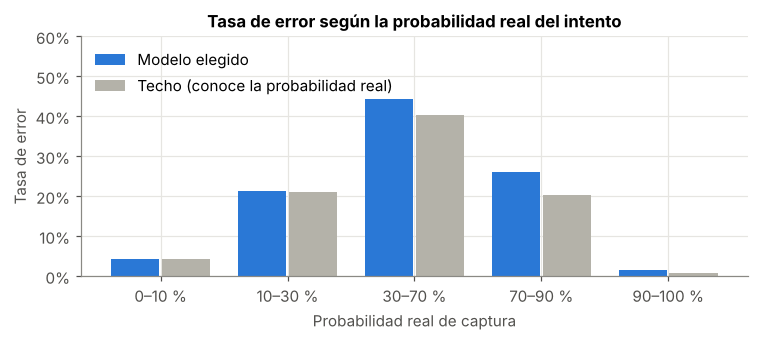

          intentos  error_modelo  error_techo
p_real                                       
0–10 %         975         0.042        0.042
10–30 %       1982         0.213        0.210
30–70 %       2923         0.444        0.404
70–90 %        823         0.260        0.204
90–100 %      1577         0.015        0.009


In [15]:
pru = datos.iloc[idx_pru].copy()
pru["p_modelo"], pru["pred"] = p_pru, pred_pru
pru["error"] = pru.pred != pru.captura
pru["techo_falla"] = (pru.p_real >= 0.5).astype(int) != pru.captura
pru["tipo"] = np.select([~pru.error, pru.techo_falla], ["acierto", "error por azar"], "error del modelo")

resumen = pru.tipo.value_counts().reindex(["acierto", "error por azar", "error del modelo"])
print(pd.DataFrame({"intentos": resumen, "% del total": (100 * resumen / len(pru)).round(1)}).to_string())
n_err = int(pru.error.sum())
print(f"\nDe los {n_err:,} errores, {resumen['error por azar'] / n_err:.0%} son por azar "
      f"y {resumen['error del modelo'] / n_err:.0%} son atribuibles al modelo.")

bandas = pd.cut(pru.p_real, [0, 0.1, 0.3, 0.7, 0.9, 1.0], include_lowest=True,
                labels=["0–10 %", "10–30 %", "30–70 %", "70–90 %", "90–100 %"])
por_banda = pru.groupby(bandas, observed=True).agg(intentos=("error", "size"), error_modelo=("error", "mean"),
                                                    error_techo=("techo_falla", "mean"))
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(len(por_banda))
ax.bar(x - 0.2, por_banda.error_modelo, 0.38, color=AZUL, label="Modelo elegido")
ax.bar(x + 0.2, por_banda.error_techo, 0.38, color=GRIS, label="Techo (conoce la probabilidad real)")
ax.set_xticks(x, por_banda.index)
ax.set(title="Tasa de error según la probabilidad real del intento", xlabel="Probabilidad real de captura", ylabel="Tasa de error")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.set_ylim(0, 0.6)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()
print(por_banda.round(3).to_string())

La mayor parte de los errores ocurre en la **zona incierta** (probabilidad real entre 30 % y 70 %), donde también falla el techo. Esos errores no se pueden eliminar con un mejor modelo.

### 7.2 Ejemplos de errores

Primero, **errores por azar**: el modelo predijo el resultado más probable y salió el otro.

In [16]:
COLS_EJ = ["identifier", "bst", "capture_rate", "hp_pct", "estado", "ball", "turno", "noche_o_cueva",
           "p_modelo", "p_real", "tipo"]
COLS_EJ = COLS_EJ[:-1]
azar = pru[pru.tipo == "error por azar"]
print("Dijo CAPTURA, era probable, y el Pokémon se escapó\n")
print(azar[azar.pred == 1].sort_values("p_real", ascending=False)[COLS_EJ].head(4).round(2).to_string(index=False))
print("\nDijo NO CAPTURA, era improbable, y el Pokémon fue capturado\n")
print(azar[azar.pred == 0].sort_values("p_real")[COLS_EJ].head(4).round(2).to_string(index=False))

Dijo CAPTURA, era probable, y el Pokémon se escapó

identifier  bst  capture_rate  hp_pct     estado       ball  turno  noche_o_cueva  p_modelo  p_real
 sandshrew  300           255      72    ninguno Turno Ball      4              0      0.77    0.99
  hoothoot  262           255      79    ninguno Ultra Ball      8              1      0.87    0.96
  meganium  525            45      46  congelado Ocaso Ball      7              1      0.62    0.94
  ribombee  464            75      61 paralizado Malla Ball      5              0      0.82    0.94

Dijo NO CAPTURA, era improbable, y el Pokémon fue capturado



identifier  bst  capture_rate  hp_pct  estado       ball  turno  noche_o_cueva  p_modelo  p_real
    keldeo  580             3      83 ninguno Turno Ball      1              0      0.04    0.02
    latios  600             3      64 ninguno Ocaso Ball      4              0      0.04    0.02
 glastrier  580             3      61 ninguno Veloz Ball      5              0      0.03    0.02
    mewtwo  680             3      58 ninguno Veloz Ball      6              0      0.08    0.02


Estos casos no indican un problema del modelo: un Hoothoot con 96 % de probabilidad real se escapa 1 de cada 25 veces, y un legendario con 2 % a veces cae.

Segundo, **errores del modelo**: el resultado era el más probable, pero el modelo estimó mal la probabilidad. Se muestran los de mayor diferencia entre la probabilidad del modelo y la real (máximo dos por especie).

In [17]:
del_modelo = pru[pru.tipo == "error del modelo"].assign(dif=lambda d: d.p_modelo - d.p_real)
dos_por_especie = lambda d: d.groupby("identifier", sort=False).head(2)

print("FALSOS POSITIVOS: el modelo creyó fácil una captura que era difícil\n")
print(dos_por_especie(del_modelo[del_modelo.pred == 1].sort_values("dif", ascending=False))[COLS_EJ].head(8).round(2).to_string(index=False))
print("\nFALSOS NEGATIVOS: el modelo creyó difícil una captura que era fácil\n")
print(dos_por_especie(del_modelo[del_modelo.pred == 0].sort_values("dif"))[COLS_EJ].head(8).round(2).to_string(index=False))

FALSOS POSITIVOS: el modelo creyó fácil una captura que era difícil

identifier  bst  capture_rate  hp_pct     estado        ball  turno  noche_o_cueva  p_modelo  p_real
    mawile  380            45      16 paralizado  Malla Ball      4              1      0.82    0.34
    mawile  380            45      86    ninguno  Ocaso Ball      9              1      0.80    0.33
     kubfu  385             3       4    dormido  Ultra Ball     10              0      0.56    0.12
    arceus  720             3       3    ninguno Rápida Ball      3              1      0.52    0.10
    arceus  720             3      44  congelado Rápida Ball      3              0      0.54    0.15
  basculin  460            25      58    ninguno  Malla Ball      3              1      0.69    0.31
  basculin  460            25      58    ninguno  Malla Ball      1              0      0.69    0.31
 marshadow  600             3      27    dormido  Veloz Ball      1              1      0.55    0.20

FALSOS NEGATIVOS: el 

En estas tablas, `capture_rate` y `p_real` se muestran solo para entender el error: el modelo no los ve.

### 7.3 ¿En qué especies se equivoca más el modelo?

Para cada especie del conjunto de prueba comparamos la probabilidad promedio que da el modelo con la real. Una diferencia grande significa que el modelo juzgó mal la dificultad de esa especie.

El modelo las cree MÁS FÁCILES de lo que son:

            bst  capture_rate  es_final  p_modelo  p_real  tasa_error  diferencia
identifier                                                                       
mawile      380            45         1      0.75    0.38        0.52        0.37
arceus      720             3         1      0.37    0.06        0.05        0.31
basculin    460            25         0      0.46    0.24        0.35        0.22
bulbasaur   318            45         0      0.57    0.36        0.28        0.21
sableye     380            45         1      0.51    0.32        0.32        0.19
glimmet     350            70         0      0.63    0.44        0.42        0.18

El modelo las cree MÁS DIFÍCILES de lo que son:

             bst  capture_rate  es_final  p_modelo  p_real  tasa_error  diferencia
identifier                                                                        
watchog      420           255         1      0.57    0.90        0.45       -0.3

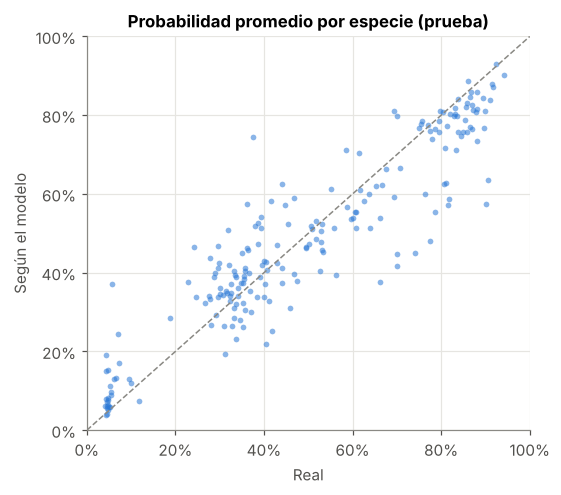

Diferencia absoluta media por especie: 0.076


In [18]:
por_especie = pru.groupby("identifier").agg(
    bst=("bst", "first"), capture_rate=("capture_rate", "first"), es_final=("es_final", "first"),
    p_modelo=("p_modelo", "mean"), p_real=("p_real", "mean"), tasa_error=("error", "mean"))
por_especie["diferencia"] = por_especie.p_modelo - por_especie.p_real

print("El modelo las cree MÁS FÁCILES de lo que son:\n")
print(por_especie.sort_values("diferencia", ascending=False).head(6).round(2).to_string())
print("\nEl modelo las cree MÁS DIFÍCILES de lo que son:\n")
print(por_especie.sort_values("diferencia").head(6).round(2).to_string())

fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.scatter(por_especie.p_real, por_especie.p_modelo, s=14, color=AZUL, alpha=0.55, linewidths=0)
ax.plot([0, 1], [0, 1], ls="--", color="#8a8984", lw=1)
ax.set(title="Probabilidad promedio por especie (prueba)", xlabel="Real", ylabel="Según el modelo", xlim=(0, 1), ylim=(0, 1))
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout(); plt.show()
print(f"Diferencia absoluta media por especie: {por_especie.diferencia.abs().mean():.3f}")

### 7.4 Errores por tipo de caso

In [19]:
def tabla_error(col, nombre):
    g = pru.groupby(col, observed=True).agg(intentos=("error", "size"), tasa_error=("error", "mean"),
                                            error_del_modelo=("tipo", lambda s: (s == "error del modelo").mean()))
    g.index.name = nombre
    return g.sort_values("error_del_modelo", ascending=False).round(3)

pru["grupo"] = np.select(
    [pru.es_ultraente == 1, pru.is_legendary + pru.is_mythical > 0, pru.etapas_restantes > 0],
    ["ultraente", "legendario o mítico", "le quedan evoluciones"], "evolución final o sin evolución")
print(tabla_error("grupo", "tipo de Pokémon").to_string(), "\n")
print(tabla_error("ball", "ball").to_string(), "\n")
print(tabla_error(pd.cut(pru.hp_pct, [0, 33, 66, 100], labels=["HP bajo", "HP medio", "HP alto"]), "HP").to_string())

                                 intentos  tasa_error  error_del_modelo
tipo de Pokémon                                                        
evolución final o sin evolución      3480       0.308             0.080
le quedan evoluciones                3800       0.230             0.064
legendario o mítico                   920       0.059             0.012
ultraente                              80       0.012             0.000 

             intentos  tasa_error  error_del_modelo
ball                                               
Ultra Ball        981       0.255             0.091
Poké Ball        1056       0.270             0.067
Turno Ball       1082       0.212             0.067
Super Ball       1013       0.238             0.063
Veloz Ball       1014       0.242             0.063
Rápida Ball      1006       0.261             0.061
Ocaso Ball       1025       0.234             0.055
Malla Ball       1103       0.224             0.050 

          intentos  tasa_error  error_del_mo

### 7.5 Qué casos son los más difíciles

1. **Intentos en la zona incierta.** Cuando la probabilidad real está entre 30 % y 70 %, el resultado es casi un sorteo. Aquí se concentra la mayoría de los errores, y no dependen del modelo.
2. **Especies cuyo ratio no sigue el patrón general.** El modelo deduce la dificultad a partir del poder, la crianza y la evolución, y falla donde los diseñadores rompieron ese patrón. Mawile y Sableye son débiles (BST 380) pero tienen ratio 45, y el modelo los cree fáciles. Watchog y Carnivine son evoluciones finales de poder medio con ratio 200 o más, y el modelo los cree difíciles. Arceus es mítico con ratio 3, y el modelo le da más probabilidad de la real porque los míticos del entrenamiento tienen ratios muy variados.
3. **Evoluciones finales y Pokémon sin evolución.** Concentran más errores propios del modelo (8,0 %) que las especies a las que les quedan evoluciones (6,4 %), porque sus ratios son más variados.
4. **Legendarios y ultraentes** casi no generan errores: casi nunca se capturan y el modelo lo aprende.
5. **Por ball y por HP no hay grandes diferencias.** La Ultra Ball tiene algo más de errores propios (9,1 %); las balls especiales no son un problema con la preparación B.

## 8. Cómo comunicar la predicción

El modelo no es infalible: acierta cerca de 3 de cada 4 veces. Por eso conviene mostrar la **probabilidad** y no solo la clase. Para eso la probabilidad tiene que ser confiable.

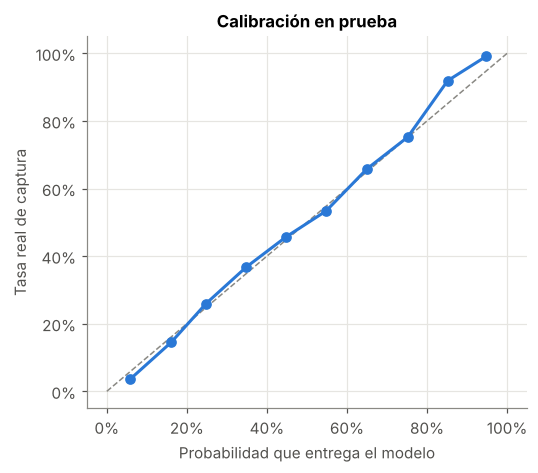

Cuando el modelo está seguro (≥ 80 % o ≤ 20 %): 39% de los intentos, exactitud 93.0%
Cuando duda (entre 40 % y 60 %): 19% de los intentos, exactitud 53.8%


In [20]:
cortes = np.linspace(0, 1, 11)
grupo = np.digitize(p_pru, cortes[1:-1])
calib = pd.DataFrame({"p": p_pru, "y": y_pru, "g": grupo}).groupby("g").agg(predicha=("p", "mean"), observada=("y", "mean"), intentos=("y", "size"))

fig, ax = plt.subplots(figsize=(5, 4.4))
ax.plot([0, 1], [0, 1], ls="--", color="#8a8984", lw=1)
ax.plot(calib.predicha, calib.observada, "o-", color=AZUL, lw=2)
ax.set(title="Calibración en prueba", xlabel="Probabilidad que entrega el modelo", ylabel="Tasa real de captura")
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout(); plt.show()

seguro = (p_pru >= 0.8) | (p_pru <= 0.2)
print(f"Cuando el modelo está seguro (≥ 80 % o ≤ 20 %): {seguro.mean():.0%} de los intentos, exactitud {accuracy_score(y_pru[seguro], pred_pru[seguro]):.1%}")
print(f"Cuando duda (entre 40 % y 60 %): {((p_pru > 0.4) & (p_pru < 0.6)).mean():.0%} de los intentos, "
      f"exactitud {accuracy_score(y_pru[(p_pru > 0.4) & (p_pru < 0.6)], pred_pru[(p_pru > 0.4) & (p_pru < 0.6)]):.1%}")

La curva sigue de cerca la diagonal: cuando el modelo dice 70 %, la tasa real de captura es cercana a 70 %. Una aplicación debería mostrar la probabilidad con un texto como *«probable», «incierto» o «poco probable»*, y advertir cuando el modelo duda.

### Ejemplo de uso: comparar balls para un mismo lanzamiento

Se toma una especie del conjunto de prueba y se repite la misma fila cambiando solo la ball.

In [21]:
def comparar_balls(nombre, hp_pct, estado, turno, noche_o_cueva):
    esp = especies[especies.identifier == nombre].iloc[0]
    filas = pd.DataFrame([{**esp[VE + ["capture_rate"]].to_dict(), "hp_pct": hp_pct, "estado": estado, "ball": b,
                           "turno": turno, "noche_o_cueva": int(noche_o_cueva)} for b in pc.BALLS])
    Xf = pd.concat([filas[VE], pc.variables_lanzamiento(filas, con_multiplicador=True)], axis=1).astype(float)[X.columns]
    out = pd.DataFrame({"ball": pc.BALLS, "P(captura) modelo": modelo_final.predict_proba(Xf)[:, 1],
                        "P(captura) real": [pc.prob_captura(esp.capture_rate, hp_pct, m, estado) for m in Xf.multiplicador_ball]})
    return out.sort_values("P(captura) modelo", ascending=False).round(3).reset_index(drop=True)

ejemplo = pru[(pru.is_legendary == 0) & (pru.es_final == 1) & (pru.tipo_water == 1)].identifier.iloc[0]
print(f"{ejemplo}: 30 % de HP, paralizado, turno 1, de noche\n")
print(comparar_balls(ejemplo, hp_pct=30, estado="paralizado", turno=1, noche_o_cueva=True).to_string(index=False))

blastoise: 30 % de HP, paralizado, turno 1, de noche

       ball  P(captura) modelo  P(captura) real
 Veloz Ball              0.807            1.000
 Malla Ball              0.676            0.799
 Ocaso Ball              0.608            0.712
 Ultra Ball              0.439            0.525
 Super Ball              0.316            0.423
  Poké Ball              0.234            0.312
Rápida Ball              0.234            0.312
 Turno Ball              0.234            0.312


## 9. Conclusiones

1. **Modelo seleccionado:** Gradient Boosting con las variables del Pokémon, del lanzamiento y el multiplicador de la ball, con árboles de 8 hojas.
2. **Por qué ese:** cuatro alternativas empataron en F1 macro; se eligió la de mejor Brier, que además es la más simple del grupo.
3. **Desempeño en prueba**, con familias evolutivas nunca vistas: F1 macro 0,758, exactitud 75,8 %, AUC 0,848. El techo alcanzable es 0,779 de F1 macro.
4. **Por clase:** el modelo es conservador. Detecta el 81 % de las *no captura* y el 71 % de las *captura*; cuando dice *captura* acierta el 78 %.
5. **Qué aportó cada decisión:** incluir las características del Pokémon sube el F1 macro de 0,61 a 0,70; el multiplicador de la ball mejora a todos los algoritmos; Gradient Boosting supera a los demás.
6. **Errores:** el 73 % se debe al azar del propio juego. Los atribuibles al modelo (6,4 % de los intentos) se concentran en especies cuyo ratio de captura rompe el patrón general.
7. **Uso:** la predicción debe comunicarse como probabilidad, no como una respuesta segura. Cuando el modelo está seguro acierta el 93 %; cuando duda, poco más que una moneda.

**Limitaciones:** los registros son simulados con la fórmula oficial (notebook 01, sección 8). Los resultados describen qué tan bien el modelo reproduce el comportamiento del juego, no el de jugadores reales.